# Basket analysis on the order items: how do lines make pairs?

**Week 4, Wednesday, chapter 5 of the concept block.** The topic, in the curriculum's words: *Basket analysis on the order items*.
The examples are invented for this chapter, small enough to count by hand: every number below is counted from a table in `data/`, and the code only confirms the count.

**Who needs the answer.** Anyone who must count every pair of a real shop: a warehouse stores a bill as order lines, one row per order and item, which is how Kalpa's `order_items` and Instamart's `cart_items` are kept.

**The questions on the way.** What is an order line? How does a basket become pairs? How many pairs do twelve orders hold? Why sort the two names? Which pair tops the table?

In [1]:
def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)
    assert ok, name
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})
import pandas as pd
from collections import Counter
from itertools import combinations, permutations

lines = pd.read_csv("../data/C2_W04_D03_canteen_order_lines_STUDENT.csv")
print("The canteen's order lines, invented: one row per order and item")
print(lines.to_string(index=False))
check("33 order lines in twelve orders", len(lines) == 33 and lines.order_id.nunique() == 12)
check("eight items on the menu", lines.item.nunique() == 8)

The canteen's order lines, invented: one row per order and item
order_id        item
     T01    dal rice
     T01       papad
     T01       chaas
     T02    dal rice
     T02       papad
     T02       chaas
     T03    dal rice
     T03       papad
     T03       chaas
     T04    dal rice
     T04       sabzi
     T04       chaas
     T05    dal rice
     T05       chaas
     T06    dal rice
     T06        curd
     T06       chaas
     T07        roti
     T07       papad
     T07      pickle
     T08       papad
     T08      pickle
     T09        roti
     T09       sabzi
     T09       chaas
     T10        roti
     T10       sabzi
     T10       chaas
     T11        roti
     T11       sabzi
     T11       chaas
     T12 gulab jamun
     T12        curd
PASS 33 order lines in twelve orders
PASS eight items on the menu


## How many pairs do the twelve orders hold?

Week 2 Thursday grouped order lines by order. Here the group becomes a set of items, so
each basket counts an item once, and every two items in a basket make a pair.

**Predict before you run.** The twelve orders hold 33 lines. Counted once per basket, how
many pairs do they hold?

a) 33, one pair for every order line.
b) 30, three pairs for each three-line order and one for each two-line order.
c) 60, every pair counted in both orders of its two names.
d) 28, every pair the eight menu items could form.

In [2]:
baskets = lines.groupby("order_id").item.apply(set)      # one set of items per order
t01 = sorted(baskets["T01"])
print("T01 holds", ", ".join(t01), "and so the pairs", list(combinations(t01, 2)))
pair_count = Counter(p for b in baskets for p in combinations(sorted(b), 2))
print(f"pairs counted once per order: {sum(pair_count.values())}; distinct pairs: {len(pair_count)}")
check("33 lines make 30 pairs", sum(pair_count.values()) == 30)
check("13 distinct pairs", len(pair_count) == 13)

T01 holds chaas, dal rice, papad and so the pairs [('chaas', 'dal rice'), ('chaas', 'papad'), ('dal rice', 'papad')]
pairs counted once per order: 30; distinct pairs: 13
PASS 33 lines make 30 pairs
PASS 13 distinct pairs


**What happened.** The answer is b. A basket of three items holds three pairs, four items
hold six, and k items hold k x (k - 1) / 2: nine three-line orders give
27 and three two-line orders give 3, so
30. `combinations` of a sorted basket gives each pair once with
its names in order (Python's itertools documentation, checked 13 October 2026). **The
trap, exactly:** keys left unsorted, so chaas with dal rice and dal rice with chaas become
two keys and the count reads 60, every pair doubled.

names left unsorted, every pair in both orders: 60 counts
9 three-line orders give 27; 3 two-line orders give 3


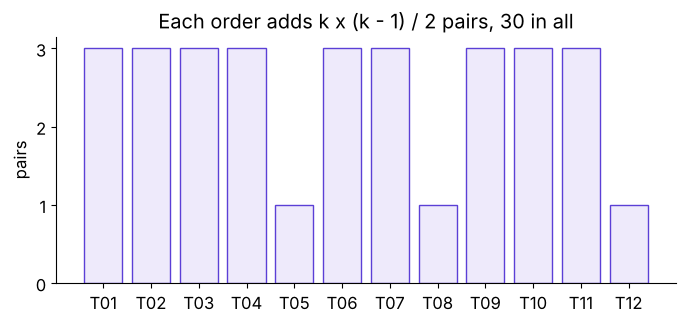

PASS unsorted keys double the count


In [3]:
both_orders = Counter(p for b in baskets for p in permutations(b, 2))
print(f"names left unsorted, every pair in both orders: {sum(both_orders.values())} counts")
size = baskets.apply(len)
per_order = size * (size - 1) // 2
print(f"{(size == 3).sum()} three-line orders give {per_order[size == 3].sum()}; "
      f"{(size == 2).sum()} two-line orders give {per_order[size == 2].sum()}")
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(per_order.index, per_order.values, color="#EEEAFB", edgecolor="#5B3FD6")
ax.set_ylabel("pairs")
ax.set_yticks([0, 1, 2, 3])
ax.set_title("Each order adds k x (k - 1) / 2 pairs, 30 in all")
plt.show()
check("unsorted keys double the count", sum(both_orders.values()) == 2 * sum(pair_count.values()))

## What does the pairs table hold?

With the pair counts and each item's own count, every pair gets chapters 1 to 3's three
numbers: support, confidence both ways, and lift. The table is sorted by count.

                    both  support  conf_a_to_b  conf_b_to_a  lift
pair                                                             
chaas + dal rice       6     0.50         0.67         1.00  1.33
chaas + sabzi          4     0.33         0.44         1.00  1.33
roti + sabzi           3     0.25         0.75         0.75  2.25
dal rice + papad       3     0.25         0.50         0.60  1.20
chaas + roti           3     0.25         0.33         0.75  1.00
chaas + papad          3     0.25         0.33         0.60  0.80
papad + pickle         2     0.17         0.40         1.00  2.40
curd + gulab jamun     1     0.08         0.50         1.00  6.00
pickle + roti          1     0.08         0.50         0.25  1.50
curd + dal rice        1     0.08         0.50         0.17  1.00
chaas + curd           1     0.08         0.11         0.50  0.67
papad + roti           1     0.08         0.20         0.25  0.60
dal rice + sabzi       1     0.08         0.17         0.25  0.50


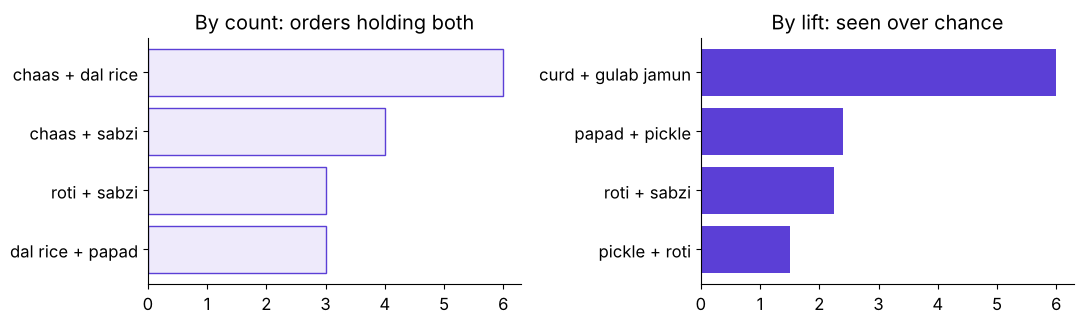

PASS roti and sabzi read back chapters 1 to 3: 3 orders, 0.25, 0.75, 2.25


In [4]:
n = len(baskets)
single = Counter(x for b in baskets for x in b)
table = pd.DataFrame([{"pair": f"{a} + {b}", "both": k, "support": k / n,
                       "conf_a_to_b": k / single[a], "conf_b_to_a": k / single[b],
                       "lift": k * n / (single[a] * single[b])}
                      for (a, b), k in pair_count.items()]).set_index("pair")
print(table.sort_values(["both", "lift"], ascending=False).round(2).to_string())
by_count = table.sort_values(["both", "lift"], ascending=False).head(4)
by_lift = table.sort_values(["lift", "both"], ascending=False).head(4)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.4))
a1.barh(by_count.index[::-1], by_count.both[::-1], color="#EEEAFB", edgecolor="#5B3FD6")
a1.set_title("By count: orders holding both")
a2.barh(by_lift.index[::-1], by_lift.lift[::-1], color="#5B3FD6")
a2.set_title("By lift: seen over chance")
plt.tight_layout()
plt.show()
r = table.loc["roti + sabzi"]
check("roti and sabzi read back chapters 1 to 3: 3 orders, 0.25, 0.75, 2.25",
      (r.both, r.support, r.conf_a_to_b, r.lift) == (3, 0.25, 0.75, 2.25))

## Why do the two rankings disagree?

By count, dal rice and chaas lead with 6 orders at lift
1.33; by lift, gulab jamun and curd lead at
6.00 on one order. A count rewards the popular item, and a
lift on one order rewards luck, so the table holds counts and never a ranking: which pair
to promote is chapter 6's decision. The grid below is the whole table at a glance, the
orders each pair of items shares.

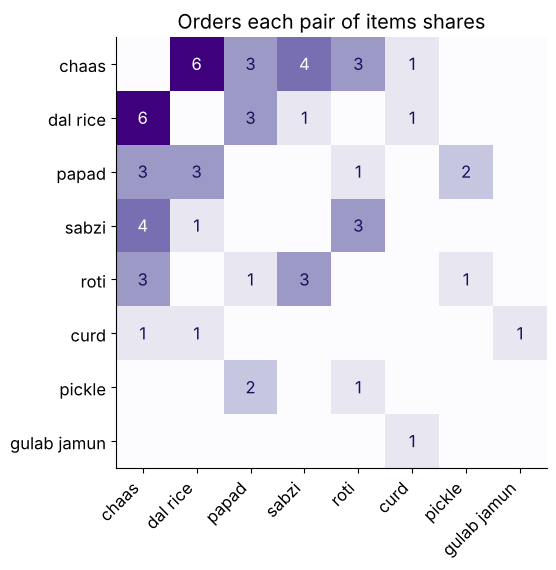

PASS the grid is symmetric and holds every pair count twice


In [5]:
menu = [x for x, _ in single.most_common()]
grid = pd.DataFrame(0, index=menu, columns=menu)
for (a, b), k in pair_count.items():
    grid.loc[a, b] = grid.loc[b, a] = k
fig, ax = plt.subplots(figsize=(6.4, 5.6))
ax.imshow(grid.values, cmap="Purples")
for i in range(len(menu)):
    for j in range(len(menu)):
        if grid.iloc[i, j]:
            ax.text(j, i, grid.iloc[i, j], ha="center", va="center", color="#1A0F5C" if grid.iloc[i, j] < 4 else "white")
ax.set_xticks(range(len(menu)), menu, rotation=45, ha="right")
ax.set_yticks(range(len(menu)), menu)
ax.set_title("Orders each pair of items shares")
plt.show()
check("the grid is symmetric and holds every pair count twice", (grid.values == grid.values.T).all()
      and grid.values.sum() == 2 * sum(pair_count.values()))

### Your turn: how many pairs does a four-item order add?

A thirteenth order arrives with roti, sabzi, chaas and papad. In the empty cell below,
build its pairs with `combinations(sorted(...), 2)` and store how many there are as
`t13_pairs`. Then run the check under it.

In [6]:
reference = len(list(combinations(sorted({"roti", "sabzi", "chaas", "papad"}), 2)))
mine = globals().get("t13_pairs")
print(f"reference: {reference} pairs" + ("" if mine is None else f"; yours: {mine}"))
check("a basket of four items adds six pairs, 4 x 3 / 2", reference == 6)
if mine is not None:
    check("your count matches the reference", mine == reference)

reference: 6 pairs
PASS a basket of four items adds six pairs, 4 x 3 / 2


## What should you keep from chapter 5?

- Group the order lines by order into a set of items, so each basket counts an item once.
- Count every two items in a basket with the two names sorted, so each pair has one key.
- A one-item basket adds no pair, and k items add k x (k - 1) / 2:
  33 lines made 30 pairs here.
- The table holds counts; which pair to promote is the next chapter's decision.

**In the interview.** "Why sort the pair's names before counting?" So that each pair has
one key and no count is split or doubled. Chapter 8 runs these lines on 40,000 Instamart
carts, and the lab on Kalpa's `order_items`.